In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn scipy

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans, AgglomerativeClustering

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
wine = load_wine()

X = wine.data
feature_names = wine.feature_names

df = pd.DataFrame(X, columns=feature_names)

print("Dataset loaded successfully!")
print()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!

Number of rows: 178
Number of columns: 13


In [ ]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
print("Dataset Information")
print("=" * 50)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
for column in df.columns:
    print(column)

Dataset Information
Rows: 178
Columns: 13

Column Names:
alcohol
malic_acid
ash
alcalinity_of_ash
magnesium
total_phenols
flavanoids
nonflavanoid_phenols
proanthocyanins
color_intensity
hue
od280/od315_of_diluted_wines
proline


In [ ]:
df.dtypes

,0
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


In [ ]:
print("Missing Values")
print("=" * 50)

print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total Missing Values: 0


In [ ]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (178, 13)


In [ ]:
print("Wine Chemical Features")
print("=" * 50)

for i, feature in enumerate(df.columns, start=1):
    print(i, "-", feature)

Wine Chemical Features
1 - alcohol
2 - malic_acid
3 - ash
4 - alcalinity_of_ash
5 - magnesium
6 - total_phenols
7 - flavanoids
8 - nonflavanoid_phenols
9 - proanthocyanins
10 - color_intensity
11 - hue
12 - od280/od315_of_diluted_wines
13 - proline


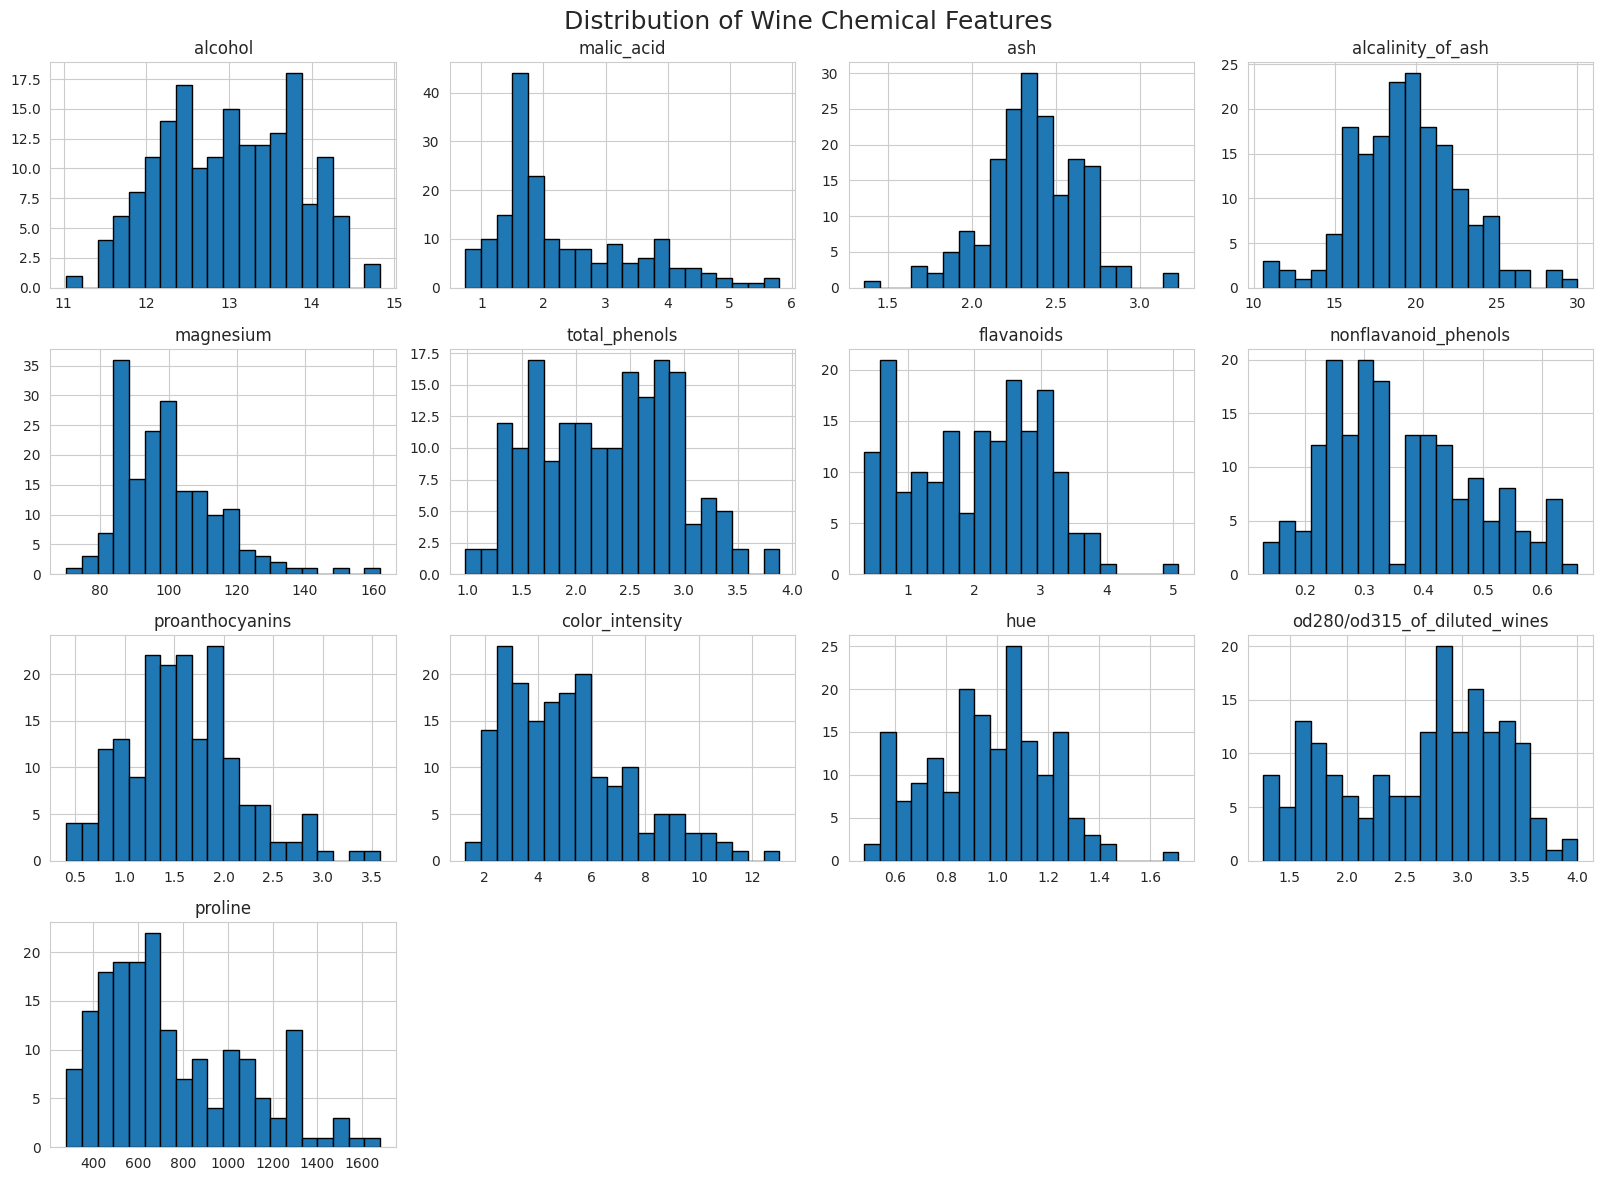

In [ ]:
df.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Wine Chemical Features",
    fontsize=18
)

plt.tight_layout()
plt.show()

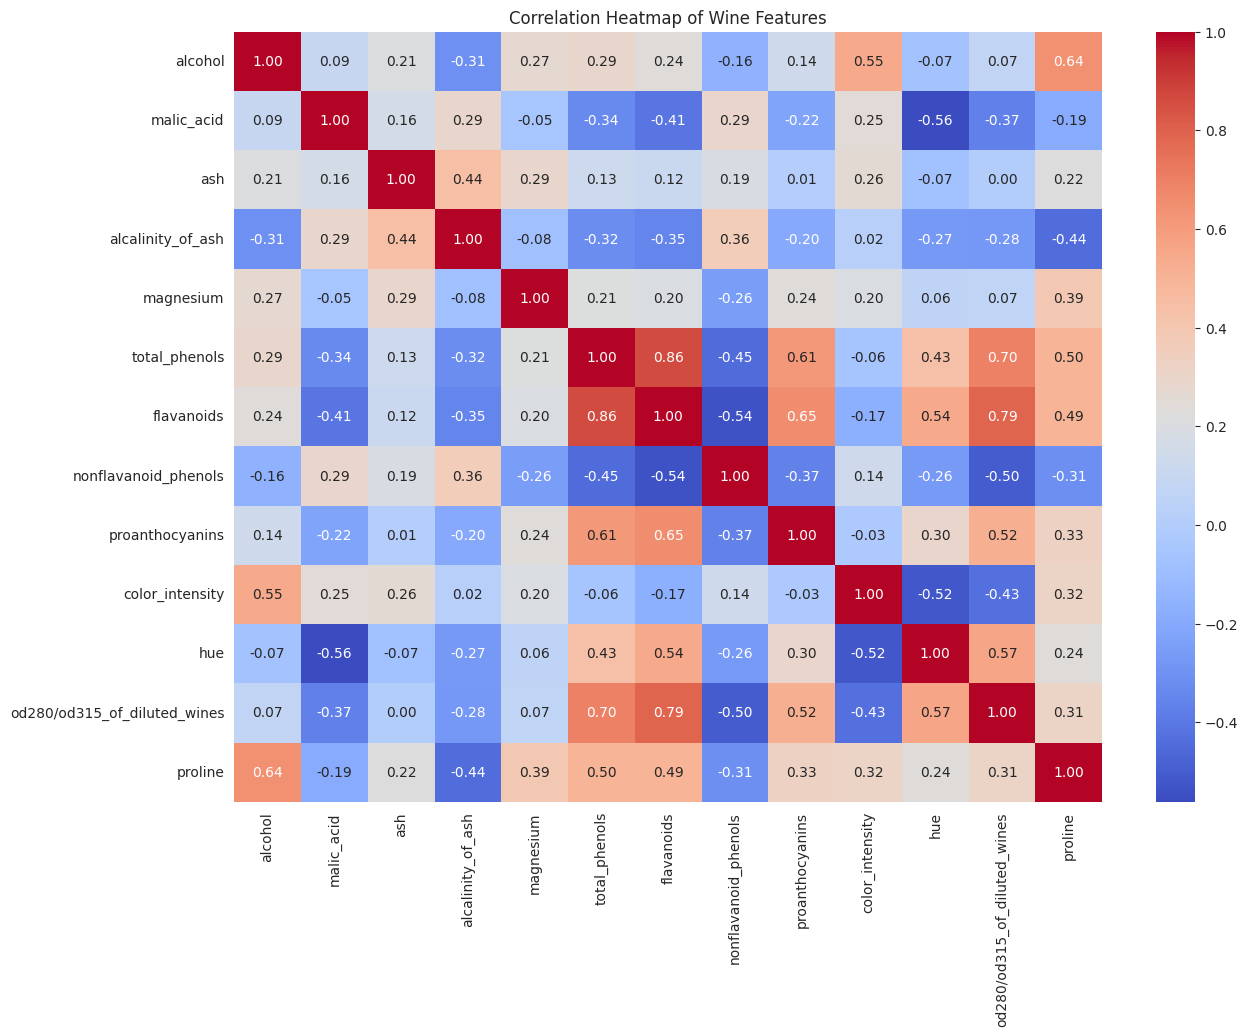

In [ ]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Wine Features")
plt.show()

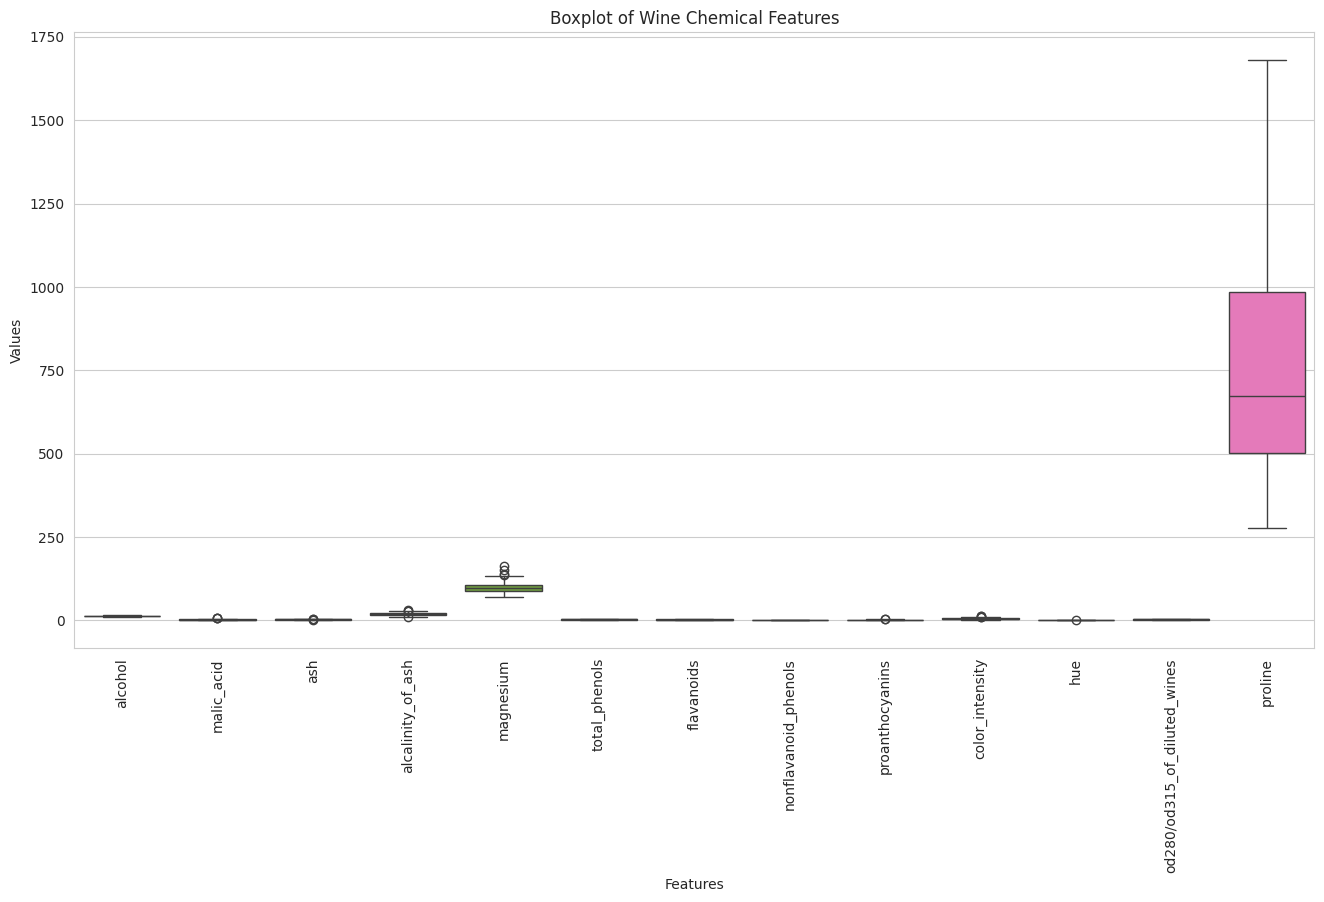

In [ ]:
plt.figure(figsize=(16, 8))

sns.boxplot(data=df)

plt.xticks(rotation=90)
plt.title("Boxplot of Wine Chemical Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.show()

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=df.columns
)

print("Standardization completed!")

Standardization completed!


In [ ]:
X_scaled.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


In [ ]:
print("Mean after standardization:")
print(X_scaled.mean().round(2))

print("\nStandard deviation after standardization:")
print(X_scaled.std().round(2))

Mean after standardization:
alcohol                         0.0
malic_acid                      0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                  -0.0
flavanoids                      0.0
nonflavanoid_phenols           -0.0
proanthocyanins                -0.0
color_intensity                -0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Standard deviation after standardization:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline       

In [ ]:
inertia = []

K_range = range(1, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

print("Inertia values:")
print(inertia)

Inertia values:
[2313.999999999999, 1658.758852429096, 1277.928488844643, 1175.4283331033473, 1109.5127392938246, 1046.002333214364, 981.5952326111659, 935.2012114738552, 889.8929111933174, 845.8952366525515]


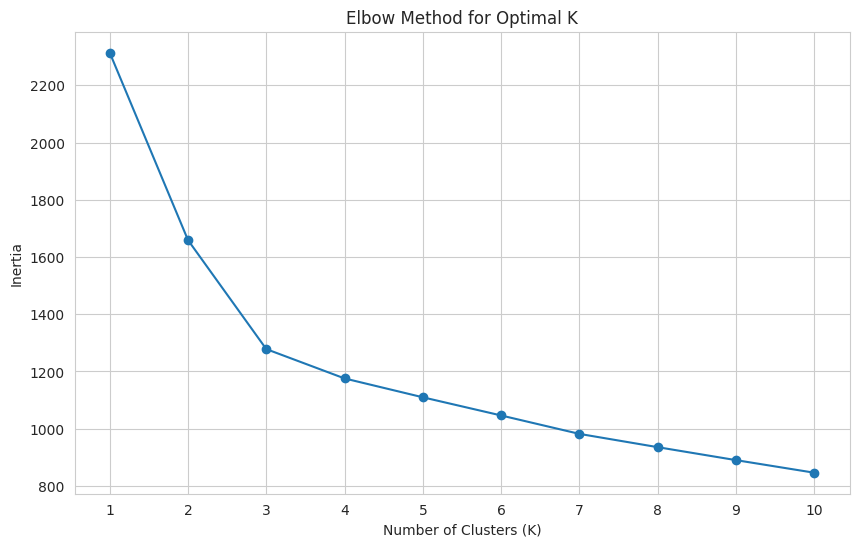

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.title("Elbow Method for Optimal K")

plt.xticks(K_range)

plt.show()

In [ ]:
silhouette_scores = []

K_range = range(2, 11)

for k in K_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

print("Silhouette Scores:")

for k, score in zip(K_range, silhouette_scores):
    print("K =", k, "Score =", round(score, 4))

Silhouette Scores:
K = 2 Score = 0.2593
K = 3 Score = 0.2849
K = 4 Score = 0.2602
K = 5 Score = 0.2016
K = 6 Score = 0.2372
K = 7 Score = 0.2036
K = 8 Score = 0.157
K = 9 Score = 0.1499
K = 10 Score = 0.1436


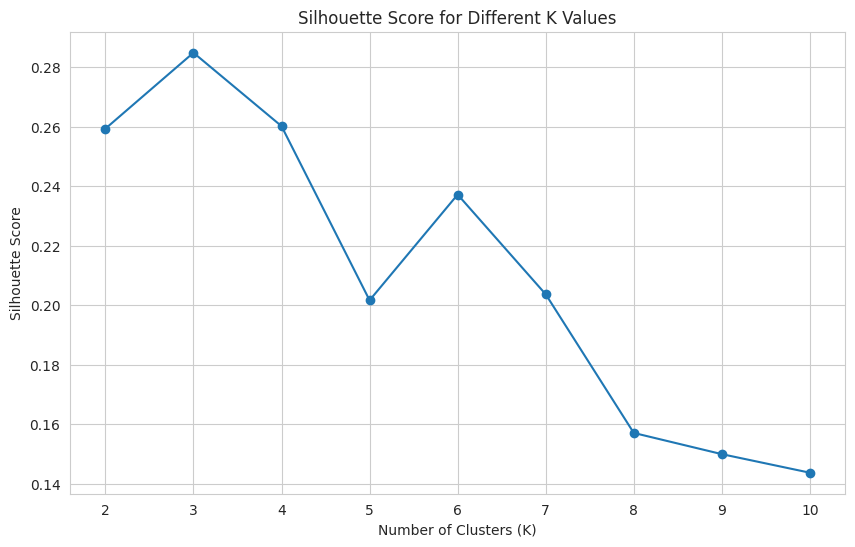

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("Silhouette Score for Different K Values")

plt.xticks(K_range)

plt.show()

In [ ]:
optimal_k = 3

print("Selected number of clusters:", optimal_k)

Selected number of clusters: 3


In [ ]:
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

K-Means clustering completed!


In [ ]:
kmeans_result = df.copy()

kmeans_result["KMeans_Cluster"] = kmeans_labels

kmeans_result.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,KMeans_Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2


In [ ]:
print("K-Means Cluster Distribution")
print("=" * 40)

print(
    kmeans_result["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)


K-Means Cluster Distribution
KMeans_Cluster
0    65
1    51
2    62
Name: count, dtype: int64


In [ ]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print(
    "K-Means Silhouette Score:",
    round(kmeans_silhouette, 4)
)


K-Means Silhouette Score: 0.2849


In [ ]:
kmeans_ch = calinski_harabasz_score(
    X_scaled,
    kmeans_labels
)

print(
    "K-Means Calinski-Harabasz Score:",
    round(kmeans_ch, 4)
)

K-Means Calinski-Harabasz Score: 70.94


In [ ]:
kmeans_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

print(
    "K-Means Davies-Bouldin Score:",
    round(kmeans_db, 4)
)

K-Means Davies-Bouldin Score: 1.3892


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA completed!")

print(
    "Explained variance by PC1:",
    round(pca.explained_variance_ratio_[0], 4)
)

print(
    "Explained variance by PC2:",
    round(pca.explained_variance_ratio_[1], 4)
)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

PCA completed!
Explained variance by PC1: 0.362
Explained variance by PC2: 0.1921
Total explained variance: 0.5541


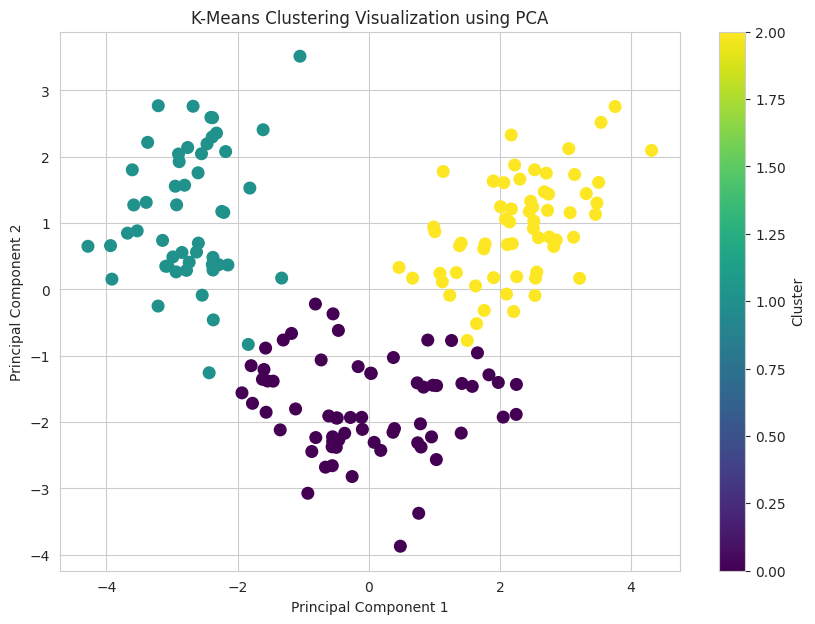

In [ ]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("K-Means Clustering Visualization using PCA")

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.show()

In [ ]:
print("K-Means Cluster Centers")
print("=" * 50)

cluster_centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=df.columns
)

cluster_centers

K-Means Cluster Centers


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,-0.926072,-0.394042,-0.494517,0.170602,-0.491712,-0.075983,0.020813,-0.033534,0.058266,-0.901914,0.461804,0.270764,-0.753846
1,0.164907,0.871547,0.186898,0.524367,-0.075473,-0.979330,-1.215248,0.726064,-0.779706,0.941539,-1.164789,-1.292412,-0.407088
2,0.835232,-0.303810,0.364706,-0.610191,0.577587,0.885237,0.977820,-0.562090,0.580287,0.171063,0.473984,0.779247,1.125185


In [ ]:
cluster_profile = (
    kmeans_result
    .groupby("KMeans_Cluster")
    .mean()
)

cluster_profile

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
KMeans_Cluster,,,,,,,,,,,,,
0,12.250923,1.897385,2.231231,20.063077,92.738462,2.247692,2.050000,0.357692,1.624154,2.973077,1.062708,2.803385,510.169231
1,13.134118,3.307255,2.417647,21.241176,98.666667,1.683922,0.818824,0.451961,1.145882,7.234706,0.691961,1.696667,619.058824
2,13.676774,1.997903,2.466290,17.462903,107.967742,2.847581,3.003226,0.292097,1.922097,5.453548,1.065484,3.163387,1100.225806


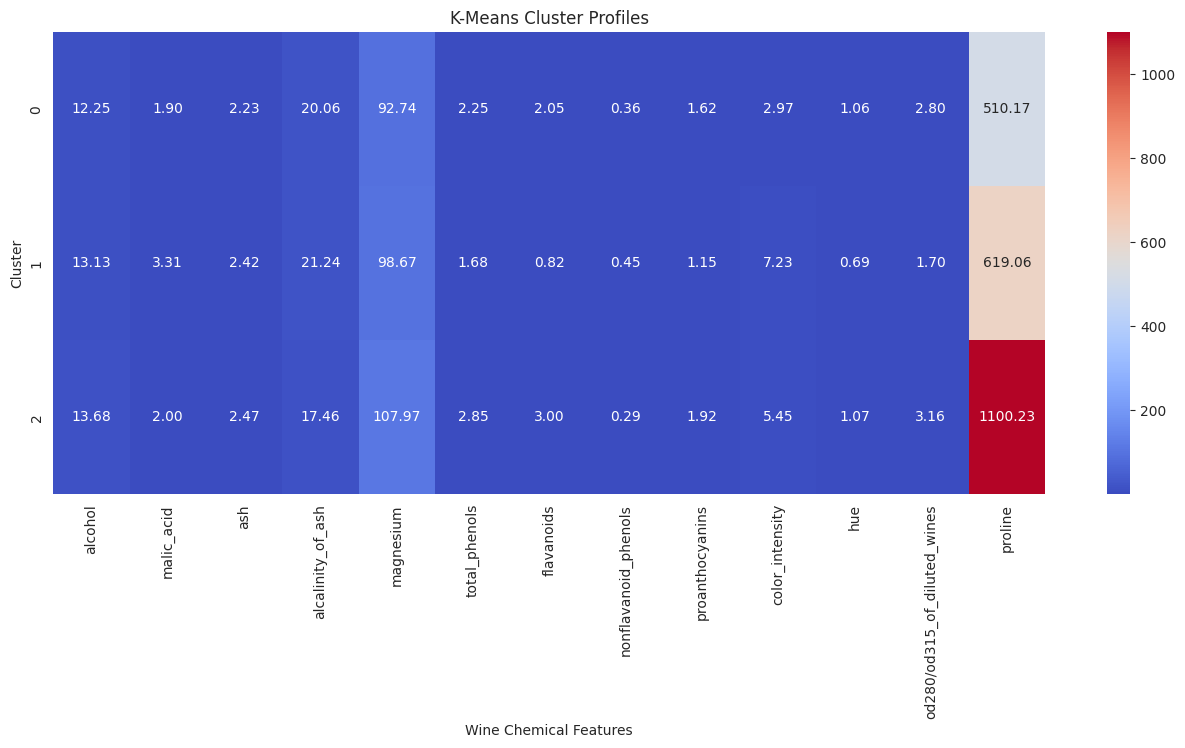

In [ ]:
plt.figure(figsize=(16, 6))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("K-Means Cluster Profiles")

plt.xlabel("Wine Chemical Features")
plt.ylabel("Cluster")

plt.xticks(rotation=90)

plt.show()

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

print("Hierarchical clustering completed!")

Hierarchical clustering completed!


In [ ]:
hierarchical_result = df.copy()

hierarchical_result[
    "Hierarchical_Cluster"
] = hierarchical_labels

hierarchical_result.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Hierarchical_Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2


In [ ]:
print("Hierarchical Cluster Distribution")
print("=" * 50)

print(
    hierarchical_result[
        "Hierarchical_Cluster"
    ].value_counts().sort_index()
)

Hierarchical Cluster Distribution
Hierarchical_Cluster
0    58
1    56
2    64
Name: count, dtype: int64


In [ ]:
hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Silhouette Score:",
    round(hierarchical_silhouette, 4)
)

Hierarchical Silhouette Score: 0.2774


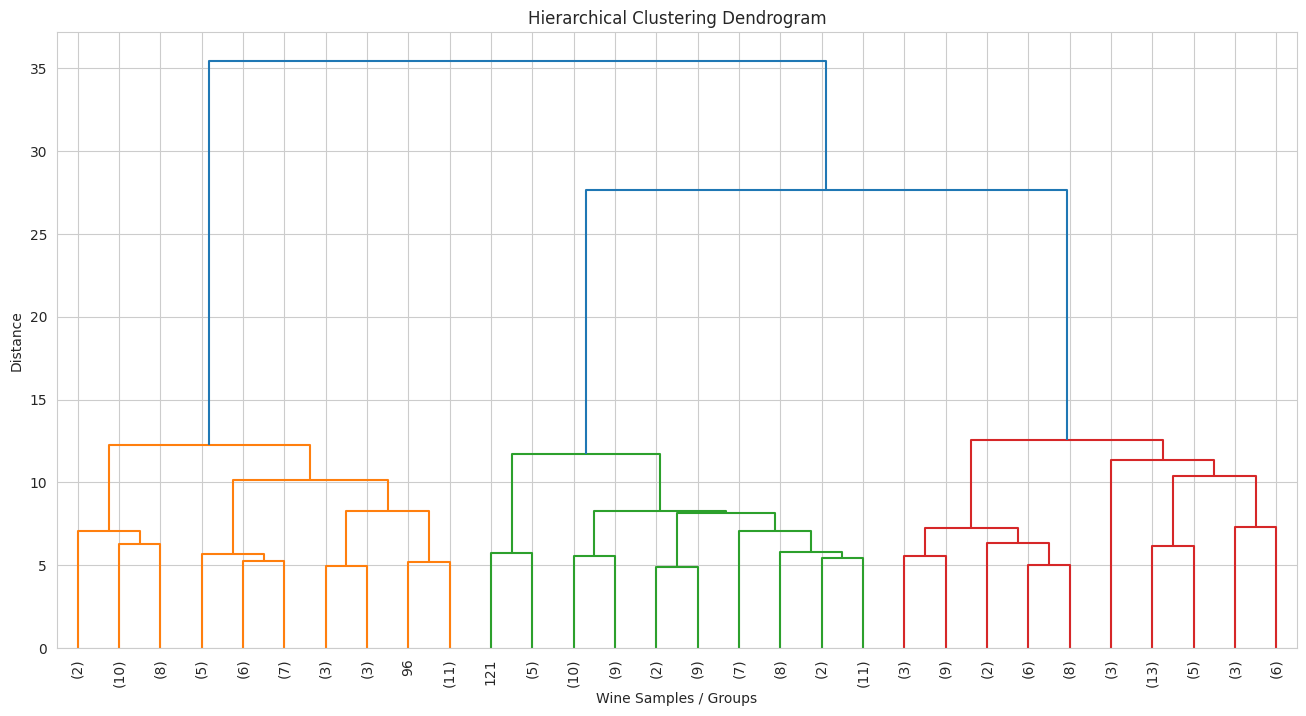

In [ ]:
linked = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(16, 8))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title(
    "Hierarchical Clustering Dendrogram"
)

plt.xlabel("Wine Samples / Groups")
plt.ylabel("Distance")

plt.show()

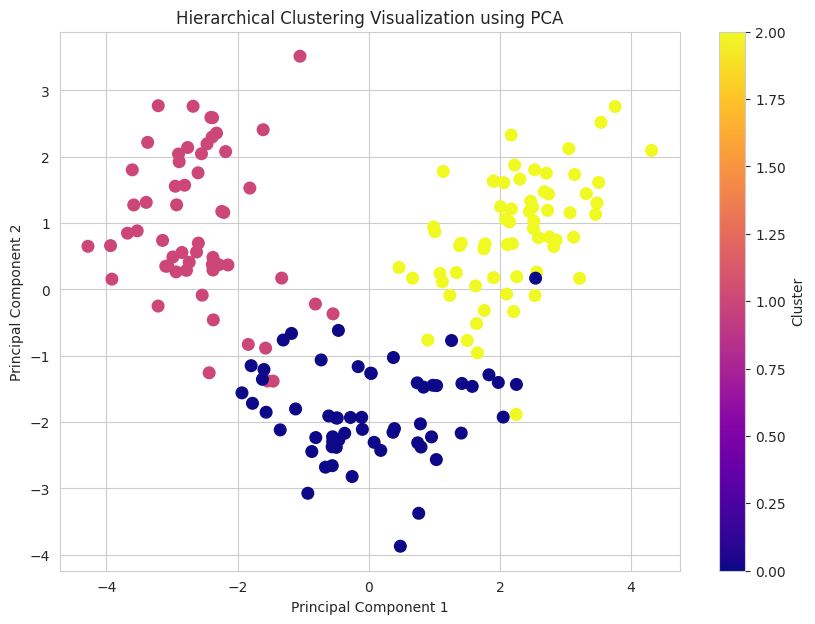

In [ ]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="plasma",
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "Hierarchical Clustering Visualization using PCA"
)

plt.colorbar(
    scatter,
    label="Cluster"
)

plt.show()

In [ ]:
hierarchical_ch = calinski_harabasz_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Calinski-Harabasz Score:",
    round(hierarchical_ch, 4)
)

Hierarchical Calinski-Harabasz Score: 67.6475


In [ ]:
hierarchical_db = davies_bouldin_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Davies-Bouldin Score:",
    round(hierarchical_db, 4)
)

Hierarchical Davies-Bouldin Score: 1.4186


In [ ]:
comparison = pd.DataFrame({

    "Model": [
        "K-Means",
        "Hierarchical Clustering"
    ],

    "Silhouette Score": [
        kmeans_silhouette,
        hierarchical_silhouette
    ],

    "Calinski-Harabasz Score": [
        kmeans_ch,
        hierarchical_ch
    ],

    "Davies-Bouldin Score": [
        kmeans_db,
        hierarchical_db
    ]

})

comparison.round(4)

,Model,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,K-Means,0.2849,70.9400,1.3892
1,Hierarchical Clustering,0.2774,67.6475,1.4186


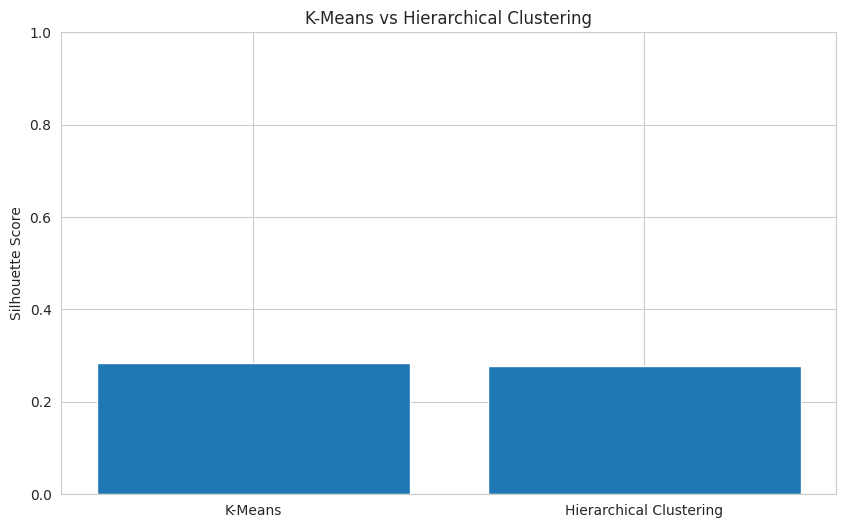

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    comparison["Model"],
    comparison["Silhouette Score"]
)

plt.ylabel("Silhouette Score")

plt.title(
    "K-Means vs Hierarchical Clustering"
)

plt.ylim(0, 1)

plt.show()

In [ ]:
comparison_clusters = pd.DataFrame({

    "Sample": range(1, len(df) + 1),

    "KMeans_Cluster": kmeans_labels,

    "Hierarchical_Cluster": hierarchical_labels

})

comparison_clusters.head(20)

,Sample,KMeans_Cluster,Hierarchical_Cluster
0,1,2,2
1,2,2,2
2,3,2,2
3,4,2,2
4,5,2,2
5,6,2,2
6,7,2,2
7,8,2,2
8,9,2,2
9,10,2,2


In [ ]:
cluster_comparison = pd.crosstab(
    comparison_clusters["KMeans_Cluster"],
    comparison_clusters["Hierarchical_Cluster"]
)

cluster_comparison

Hierarchical_Cluster,0,1,2
KMeans_Cluster,,,
0,57,5,3
1,0,51,0
2,1,0,61


In [ ]:
final_results = df.copy()

final_results["KMeans_Cluster"] = kmeans_labels

final_results["Hierarchical_Cluster"] = hierarchical_labels

final_results.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,KMeans_Cluster,Hierarchical_Cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,2,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,2,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,2,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,2,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,2,2


In [ ]:
final_results.to_csv(
    "wine_clustering_results.csv",
    index=False
)

print(
    "wine_clustering_results.csv saved successfully!"
)

wine_clustering_results.csv saved successfully!


In [ ]:
from google.colab import files

files.download(
    "wine_clustering_results.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("=" * 70)
print("                FINAL PROJECT CONCLUSION")
print("=" * 70)

print()

print("Dataset:")
print("178 wine samples with 13 chemical features.")

print()

print("K-Means:")
print(
    "Silhouette Score =",
    round(kmeans_silhouette, 4)
)

print()

print("Hierarchical Clustering:")
print(
    "Silhouette Score =",
    round(hierarchical_silhouette, 4)
)

print()

if kmeans_silhouette > hierarchical_silhouette:

    print(
        "Based on the Silhouette Score, "
        "K-Means produced the better clustering result."
    )

elif hierarchical_silhouette > kmeans_silhouette:

    print(
        "Based on the Silhouette Score, "
        "Hierarchical Clustering produced the better clustering result."
    )

else:

    print(
        "Both algorithms produced the same Silhouette Score."
    )

print()

print(
    "The project successfully identified natural groups "
    "of wine samples using their chemical characteristics."
)

print(
    "No predefined class labels were used during clustering."
)

print("=" * 70)

                FINAL PROJECT CONCLUSION

Dataset:
178 wine samples with 13 chemical features.

K-Means:
Silhouette Score = 0.2849

Hierarchical Clustering:
Silhouette Score = 0.2774

Based on the Silhouette Score, K-Means produced the better clustering result.

The project successfully identified natural groups of wine samples using their chemical characteristics.
No predefined class labels were used during clustering.


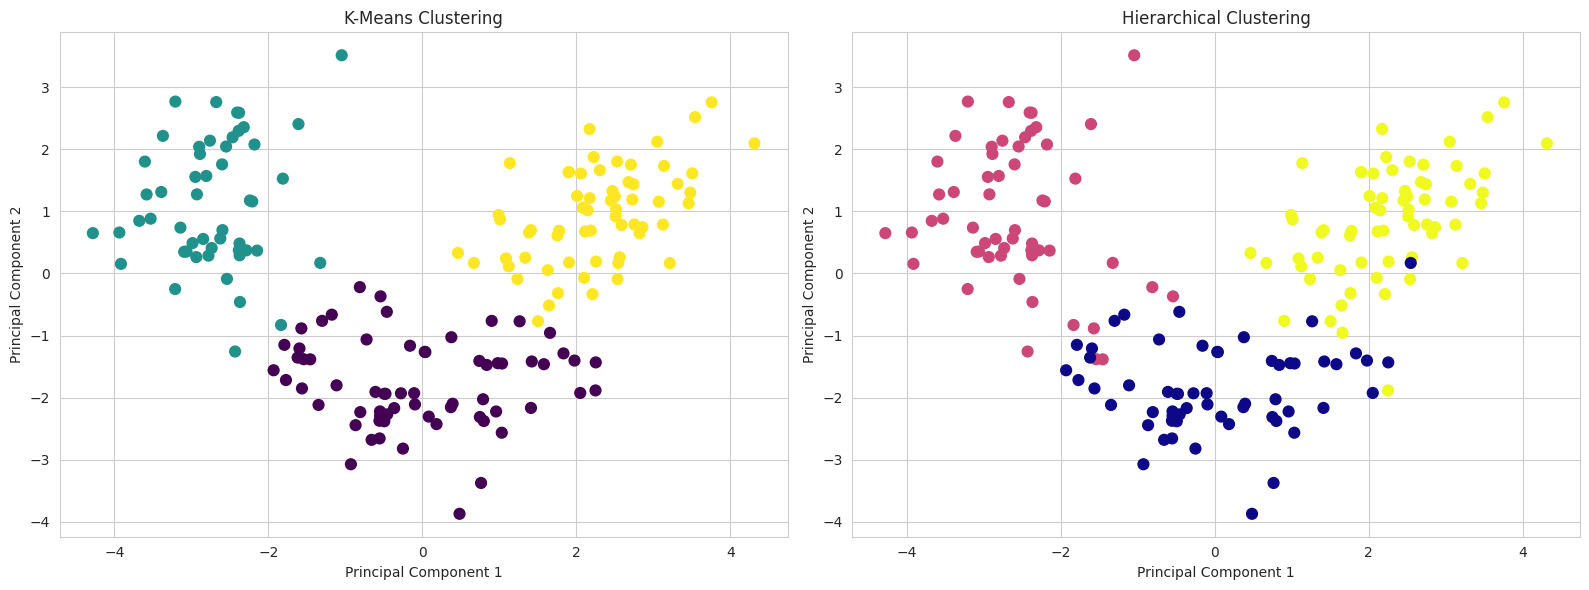

In [ ]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

# K-Means
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=60
)

axes[0].set_title(
    "K-Means Clustering"
)

axes[0].set_xlabel(
    "Principal Component 1"
)

axes[0].set_ylabel(
    "Principal Component 2"
)


# Hierarchical
axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="plasma",
    s=60
)

axes[1].set_title(
    "Hierarchical Clustering"
)

axes[1].set_xlabel(
    "Principal Component 1"
)

axes[1].set_ylabel(
    "Principal Component 2"
)

plt.tight_layout()

plt.show()